Raw train shape: (11, 65282)
X shape (channels, samples): (11, 65282)
EEG shape: (8, 65282)


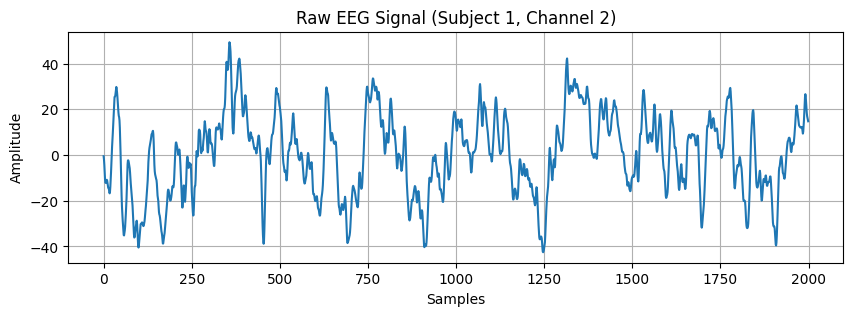

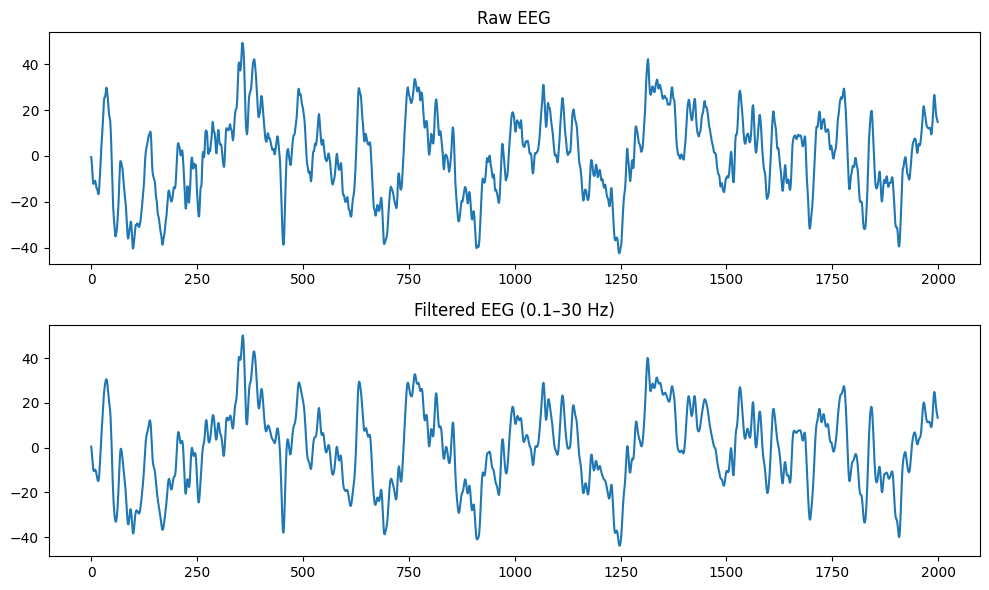

Flash events: 65281
Target events: 300
Epochs shape: (300, 240)


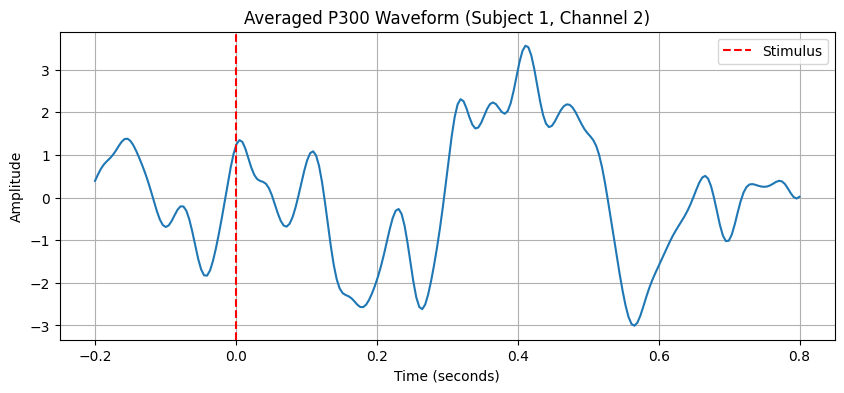

In [7]:
# ===============================
# 1. Imports
# ===============================
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.signal import butter, filtfilt

# ===============================
# 2. Load s1.mat correctly
# ===============================
data = sio.loadmat('/content/s1.mat')
s1 = data['s1']

# train is a MATLAB struct -> extract numeric matrix
train = s1['train'][0][0]

print("Raw train shape:", train.shape)

# ===============================
# 3. Fix orientation (CRITICAL)
# ===============================
# train is (samples, channels) → convert to (channels, samples)
if train.shape[0] > train.shape[1]:
    X = train.T
else:
    X = train

print("X shape (channels, samples):", X.shape)

# ===============================
# 4. Channel mapping (BNCI Visual P300)
# ===============================
# Channels:
# 0–7 : EEG
# 8   : Flash ID
# 9   : Target label

eeg    = X[0:8, :]
flash  = X[8, :]
target = X[9, :]

print("EEG shape:", eeg.shape)

# ===============================
# 5. Choose EEG channel (USE SAME EVERYWHERE)
# ===============================
eeg_channel_index = 2   # valid EEG channel

# ===============================
# 6. Bandpass filter (SAFE)
# ===============================
fs = 240

def bandpass_filter(signal, lowcut=0.1, highcut=30, fs=240, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, signal, padlen=0)

filtered_eeg = np.zeros_like(eeg)
for ch in range(eeg.shape[0]):
    filtered_eeg[ch] = bandpass_filter(eeg[ch])

# ===============================
# 7. Plot 1 — RAW EEG (CORRECT)
# ===============================
plt.figure(figsize=(10,3))
plt.plot(eeg[eeg_channel_index, :2000])
plt.title("Raw EEG Signal (Subject 1, Channel 2)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)
plt.savefig("raw_eeg_subject1_channel2.png", dpi=300)
plt.show()

# ===============================
# 8. Plot 2 — RAW vs FILTERED EEG
# ===============================
plt.figure(figsize=(10,6))

plt.subplot(2,1,1)
plt.plot(eeg[eeg_channel_index, :2000])
plt.title("Raw EEG")

plt.subplot(2,1,2)
plt.plot(filtered_eeg[eeg_channel_index, :2000])
plt.title("Filtered EEG (0.1–30 Hz)")

plt.tight_layout()
plt.savefig("raw_vs_filtered_eeg_subject1_channel2.png", dpi=300)
plt.show()

# ===============================
# 9. Flash onset detection
# ===============================
flash_starts = np.where(flash[1:] != flash[:-1])[0]
target_starts = [i for i in flash_starts if target[i] == 1]

print("Flash events:", len(flash_starts))
print("Target events:", len(target_starts))

# ===============================
# 10. Epoch extraction (-200 ms to +800 ms)
# ===============================
baseline_samples = int(0.2 * fs)
post_samples     = int(0.8 * fs)

epochs = []
for idx in target_starts:
    start = idx - baseline_samples
    end   = idx + post_samples
    if start >= 0 and end < eeg.shape[1]:
        epochs.append(filtered_eeg[eeg_channel_index, start:end])

epochs = np.array(epochs)
print("Epochs shape:", epochs.shape)

# ===============================
# 11. Baseline correction + averaging
# ===============================
baseline_corrected_epochs = (
    epochs - epochs[:, :baseline_samples].mean(axis=1, keepdims=True)
)

p300 = baseline_corrected_epochs.mean(axis=0)
time = np.linspace(-0.2, 0.8, p300.shape[0])

# ===============================
# 12. Plot 3 — FINAL AVERAGED P300
# ===============================
plt.figure(figsize=(10,4))
plt.plot(time, p300)
plt.axvline(0, color='r', linestyle='--', label='Stimulus')
plt.title("Averaged P300 Waveform (Subject 1, Channel 2)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.savefig("averaged_p300_subject1_channel2.png", dpi=300)
plt.show()
